# Retail Sales Case Study: Python Analysis

This notebook analyses daily retail sales (30 Dec 2013 to 16 Nov 2016) using pandas and matplotlib. It covers unit pricing, gross profit, promotional periods, and Price Elasticity of Demand (PED), then sets out the findings and recommendations.

**Dataset:** `Retail_Sales_Dataset.csv(Sales Master).csv`, with columns Date, Sales, Cost Of Sales and Quantity Sold.

## 1. Load and check the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA = "Retail_Sales_Dataset.csv(Sales Master).csv"

df = pd.read_csv(DATA)
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df = df.sort_values("Date").reset_index(drop=True)

print("Rows:", len(df))
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate dates:", int(df["Date"].duplicated().sum()))
df.head()

Rows: 1053
Date range: 2013-12-30 to 2016-11-16
Missing values: 0
Duplicate dates: 0


,Date,Sales,Cost Of Sales,Quantity Sold
0,2013-12-30,223937.96790,230079.62100,6827
1,2013-12-31,300345.48460,306986.12050,9268
2,2014-01-01,86782.46773,87986.31821,2678
3,2014-01-02,200173.11680,202881.17770,6175
4,2014-01-03,326906.07420,333806.29190,10084


## 2. Unit price and gross profit

- **Unit price** = Sales / Quantity Sold, calculated per day.
- **Average unit price** is reported two ways. The simple average of daily prices gives a different figure from the weighted average (total sales / total units), because busy days carry more weight in the weighted version.
- **Gross profit** = Sales − Cost Of Sales. **GP%** = Gross profit / Sales.

In [2]:
df["Unit_Price"] = df["Sales"] / df["Quantity Sold"]
df["Gross_Profit"] = df["Sales"] - df["Cost Of Sales"]
df["GP_Pct"] = df["Gross_Profit"] / df["Sales"] * 100
df["GP_Per_Unit"] = df["Gross_Profit"] / df["Quantity Sold"]

summary = pd.Series({
    "Simple average of daily unit prices": df["Unit_Price"].mean(),
    "Weighted average unit price": df["Sales"].sum() / df["Quantity Sold"].sum(),
    "Total gross profit %": df["Gross_Profit"].sum() / df["Sales"].sum() * 100,
    "Average daily GP %": df["GP_Pct"].mean(),
    "Days where cost exceeds sales": (df["Gross_Profit"] < 0).sum(),
    "Share of days where cost exceeds sales (%)": (df["Gross_Profit"] < 0).mean() * 100,
})
summary.round(2)

Simple average of daily unit prices            37.07
Weighted average unit price                    35.40
Total gross profit %                           -3.81
Average daily GP %                             -0.87
Days where cost exceeds sales                 607.00
Share of days where cost exceeds sales (%)     57.64
dtype: float64

The business is loss-making on a gross basis. Total gross profit is negative, and cost of sales exceeds sales on more than half of all trading days. The weighted unit price (about 35.40) is the figure to quote, because the simple average (about 37.07) overweights quiet days.

## 3. Trends over time

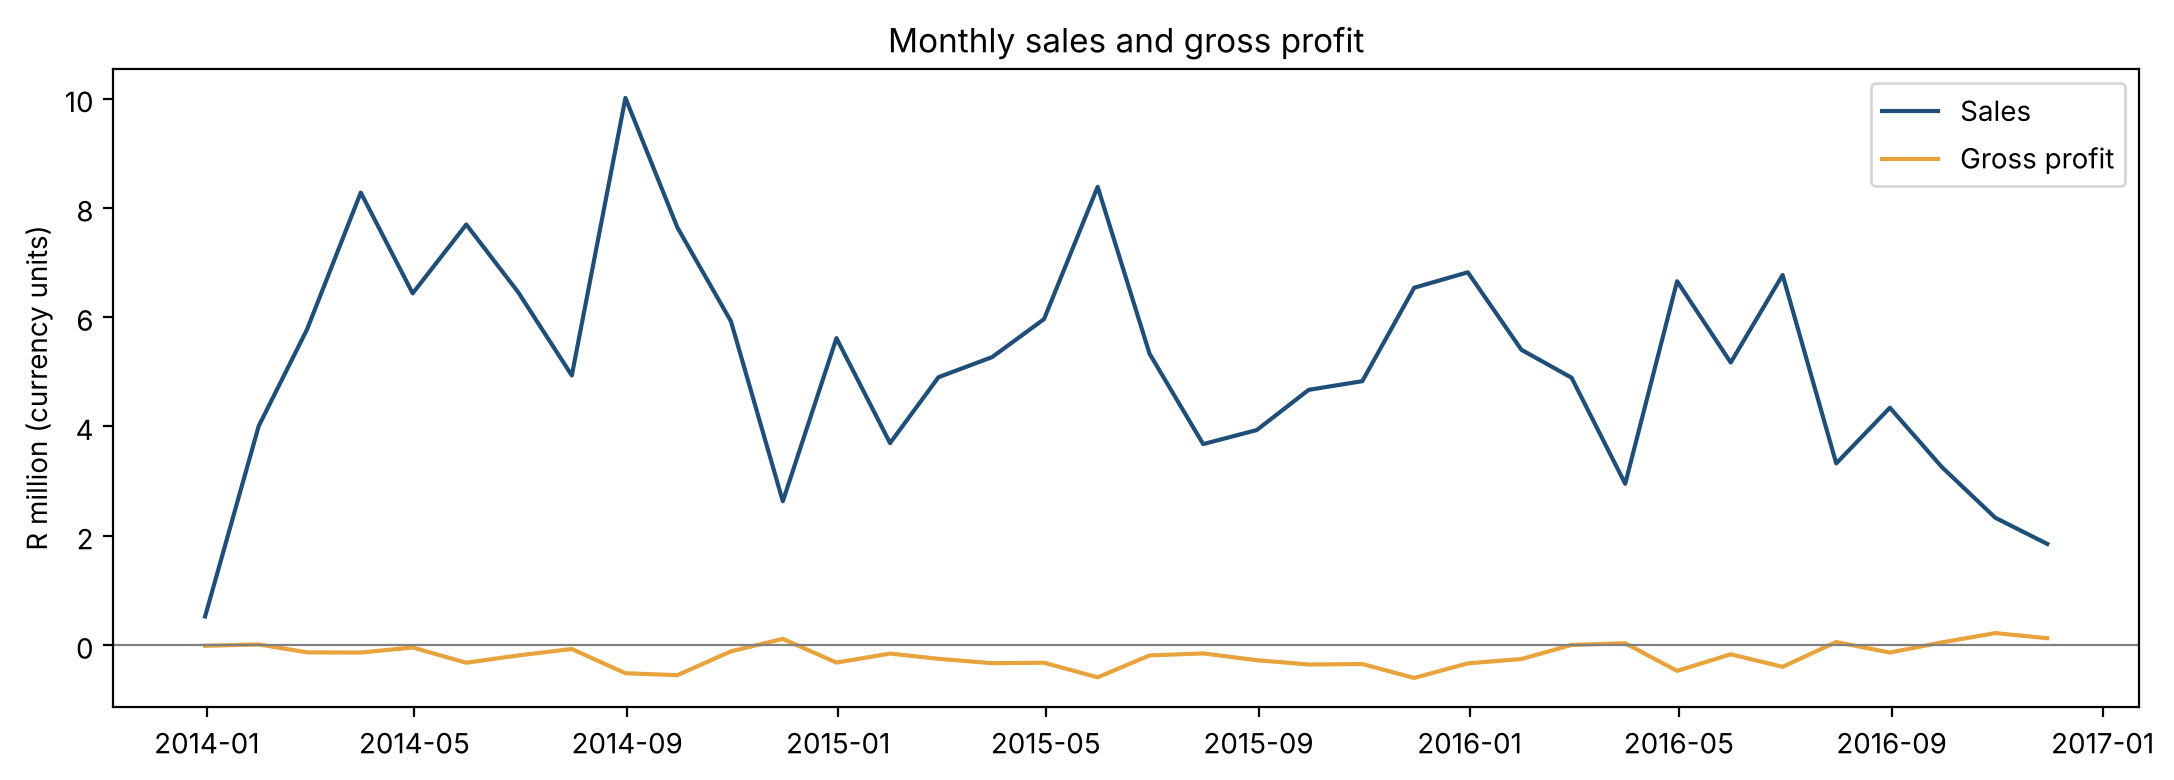

In [3]:
monthly = df.set_index("Date").resample("ME").agg(
    Sales=("Sales", "sum"),
    Gross_Profit=("Gross_Profit", "sum"),
    Quantity=("Quantity Sold", "sum"),
)
monthly["Unit_Price"] = monthly["Sales"] / monthly["Quantity"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly.index, monthly["Sales"] / 1e6, label="Sales", color="#1F4E79")
ax.plot(monthly.index, monthly["Gross_Profit"] / 1e6, label="Gross profit", color="#E8A33D")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_title("Monthly sales and gross profit")
ax.set_ylabel("R million (currency units)")
ax.legend()
plt.tight_layout()
plt.savefig("images/monthly_sales_gp.png", dpi=120)
plt.show()

## 4. Price vs quantity

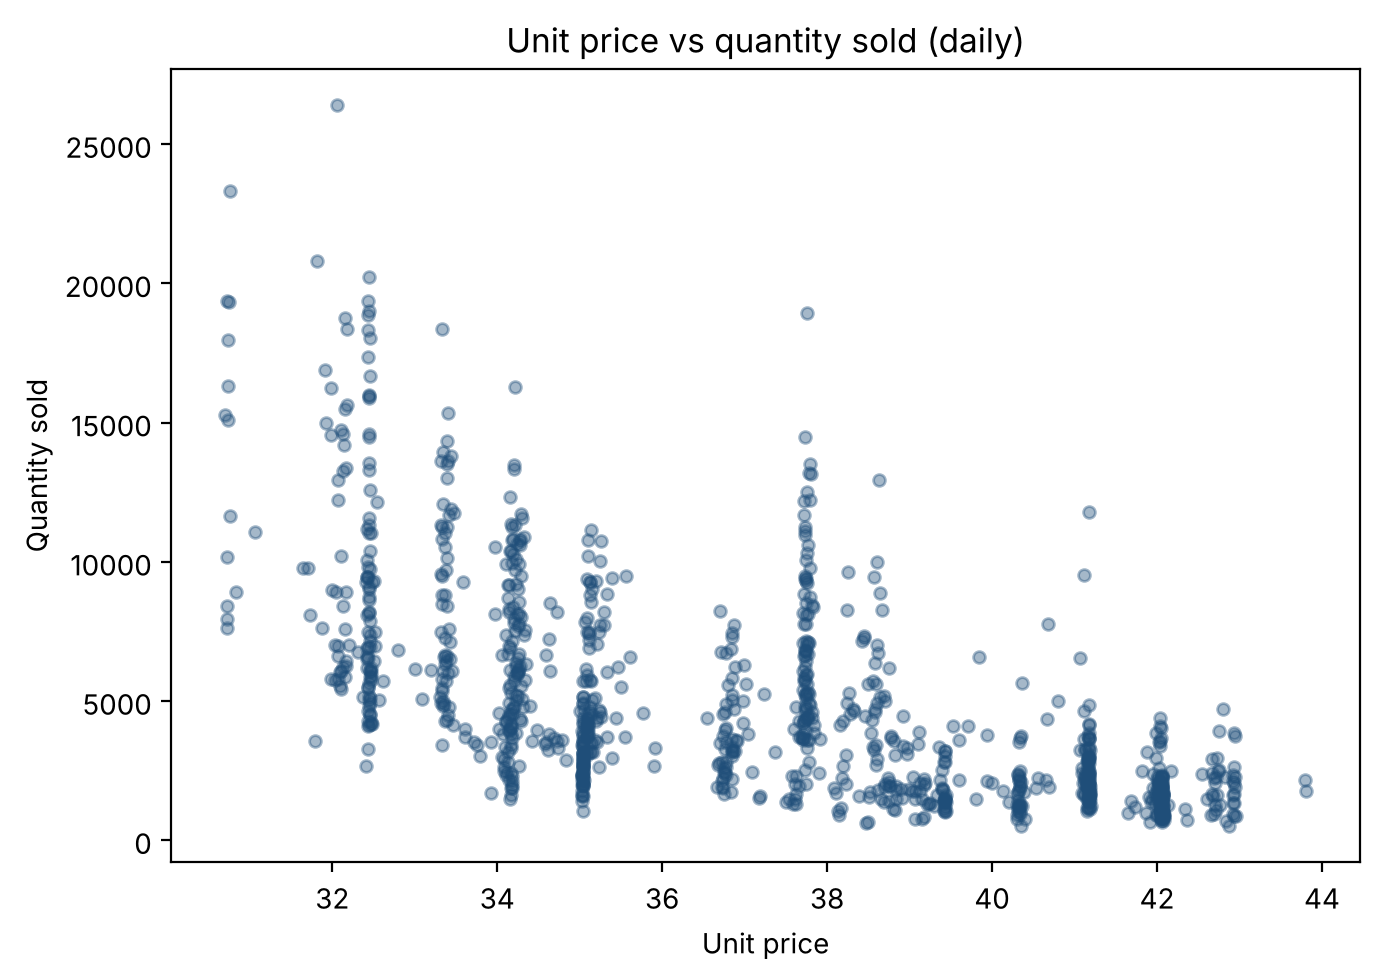

Correlation between unit price and quantity: -0.625


In [4]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["Unit_Price"], df["Quantity Sold"], alpha=0.4, color="#1F4E79", s=18)
ax.set_title("Unit price vs quantity sold (daily)")
ax.set_xlabel("Unit price")
ax.set_ylabel("Quantity sold")
plt.tight_layout()
plt.savefig("images/price_vs_quantity.png", dpi=120)
plt.show()

print("Correlation between unit price and quantity:", round(df["Unit_Price"].corr(df["Quantity Sold"]), 3))

## 5. Promotional periods

A day is flagged as promotional when:
- its unit price is at least 5% below the average of the previous 30 days, and
- its quantity sold is at least 20% above the previous 30-day average.

Consecutive flagged days are grouped into one **promotional window**. Using a 30-day rolling baseline avoids comparing promotions against a single noisy previous day.

In [5]:
df["P_Base"] = df["Unit_Price"].shift(1).rolling(30, min_periods=30).mean()
df["Q_Base"] = df["Quantity Sold"].shift(1).rolling(30, min_periods=30).mean()

df["Promo"] = (df["Unit_Price"] < 0.95 * df["P_Base"]) & (df["Quantity Sold"] > 1.2 * df["Q_Base"])

print("Promotional days:", int(df["Promo"].sum()), "of", int(df["P_Base"].notna().sum()), "assessable days")

group_id = (df["Promo"] != df["Promo"].shift()).cumsum()
promo_days = df[df["Promo"]]
windows = promo_days.groupby(group_id[df["Promo"]]).agg(
    Start=("Date", "min"),
    End=("Date", "max"),
    Days=("Date", "size"),
    Promo_Price=("Unit_Price", "mean"),
    Promo_Qty=("Quantity Sold", "mean"),
    Base_Price=("P_Base", "mean"),
    Base_Qty=("Q_Base", "mean"),
).reset_index(drop=True)
print("Promotional windows identified:", len(windows))
windows.head(10).round(2)

Promotional days: 145 of 1023 assessable days
Promotional windows identified: 49


/tmp/ipykernel_128/3439306487.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  windows.head(10).round(2)


,Start,End,Days,Promo_Price,Promo_Qty,Base_Price,Base_Qty
0,2014-02-22,2014-02-22,1,31.64,9772.00,33.36,4596.10
1,2014-02-27,2014-02-27,1,31.07,11082.00,33.04,5184.00
2,2014-05-09,2014-05-10,2,32.48,11317.00,34.30,6085.18
3,2014-05-15,2014-05-17,3,32.12,12288.33,34.06,6210.21
4,2014-07-16,2014-07-16,1,32.44,4825.00,34.40,3382.97
5,2014-07-19,2014-07-19,1,32.43,7485.00,34.61,3133.53
6,2014-07-23,2014-07-23,1,32.46,5106.00,34.81,2937.97
7,2014-07-25,2014-08-01,8,32.44,11386.25,34.48,4115.45
8,2014-08-29,2014-08-30,2,30.76,21313.50,32.64,9270.55
9,2014-09-01,2014-09-03,3,30.72,16585.67,32.44,9787.74


## 6. Price Elasticity of Demand (PED)

PED = % change in quantity sold / % change in price, measured for each promotional window against its baseline.

- A PED below −1 means demand is **elastic**: a price cut produces a proportionally larger rise in units sold.
- A PED between −1 and 0 means demand is **inelastic**.

Because the price cut is small (about 5 to 15%), the percentage changes are large in relative terms and the windows are noisy. The median is therefore more reliable than the mean for summarising the results.

In [6]:
windows["Price_Change_Pct"] = (windows["Promo_Price"] - windows["Base_Price"]) / windows["Base_Price"] * 100
windows["Qty_Change_Pct"] = (windows["Promo_Qty"] - windows["Base_Qty"]) / windows["Base_Qty"] * 100
windows["PED"] = windows["Qty_Change_Pct"] / windows["Price_Change_Pct"]

ped_summary = pd.Series({
    "Windows analysed": len(windows),
    "Mean PED": windows["PED"].mean(),
    "Median PED": windows["PED"].median(),
    "Windows with elastic PED (below -1)": (windows["PED"] < -1).sum(),
    "Average units on promo days": promo_days["Quantity Sold"].mean(),
    "Average units on non-promo days": df.loc[~df["Promo"] & df["P_Base"].notna(), "Quantity Sold"].mean(),
})
ped_summary.round(2)

Windows analysed                         49.00
Mean PED                                -14.20
Median PED                              -13.56
Windows with elastic PED (below -1)      49.00
Average units on promo days            8641.58
Average units on non-promo days        4440.41
dtype: float64

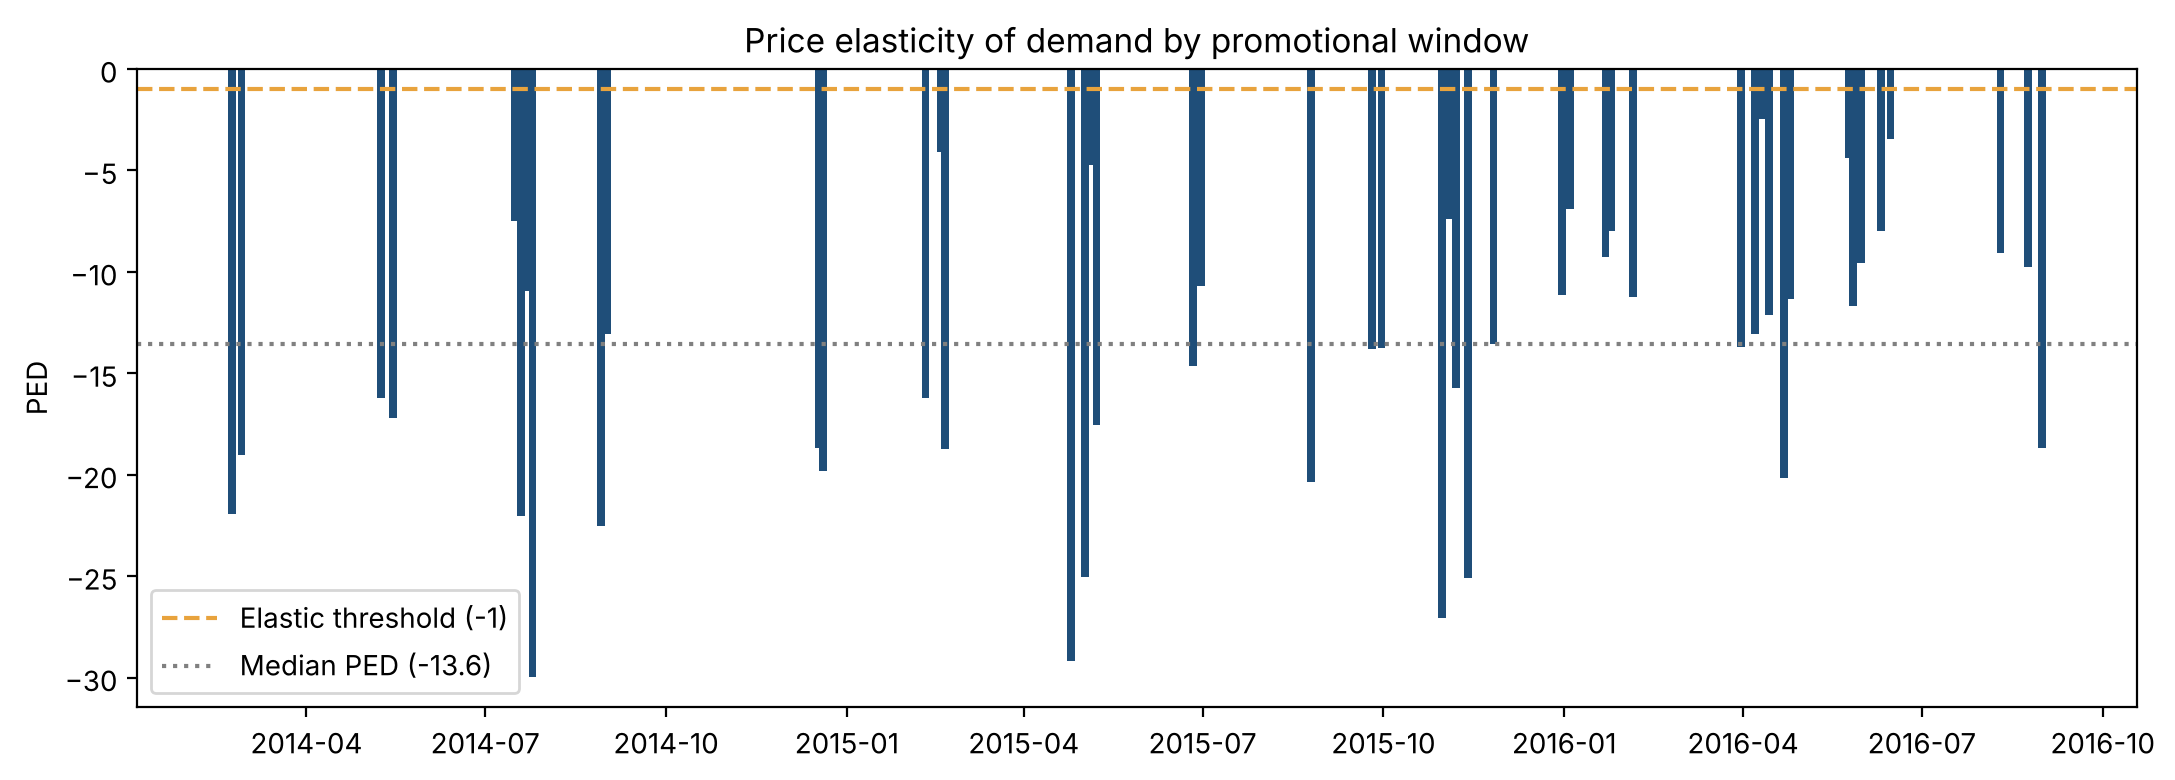

In [7]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(windows["Start"], windows["PED"], width=4, color="#1F4E79")
ax.axhline(-1, color="#E8A33D", linestyle="--", label="Elastic threshold (-1)")
ax.axhline(windows["PED"].median(), color="grey", linestyle=":", label=f"Median PED ({windows['PED'].median():.1f})")
ax.set_title("Price elasticity of demand by promotional window")
ax.set_ylabel("PED")
ax.legend()
plt.tight_layout()
plt.savefig("images/ped_by_window.png", dpi=120)
plt.show()

## 7. Findings and recommendations

**Findings**

1. **Gross margin is negative overall.** Cost of sales exceeds sales on about 58% of trading days, and total gross profit is slightly negative (about −3.8% of sales). The average daily GP% is about −0.9%.
2. **Demand responds strongly to price.** The median PED is about −13.6, so a 1% price cut has been associated with roughly a 13 to 14% rise in units. This is well above the elastic threshold of −1 for every one of the 49 windows.
3. **Promotions are the main volume driver.** Promotional days average roughly 8,600 units, against about 4,400 on non-promotional days, which is nearly double.
4. **Promotions have not fixed the margin problem.** Discounts lift volume, but the margin still goes negative on many days. Discounting alone is not enough to make the business profitable.

**Recommendations**

1. **Review cost of sales before the next promotion.** With cost above sales on most days, the first lever is cost, not price. Check supplier terms, product mix, and whether costs are allocated correctly to daily sales.
2. **Set a minimum margin for promotions.** Because demand is so price-elastic, a modest discount drives a large volume increase. Test whether a smaller discount, such as 5%, delivers most of the volume lift while protecting margin.
3. **Track PED each quarter.** Re-run the window analysis as new data arrives, so pricing decisions use the latest elasticity estimate.
4. **Prioritise the promotional calendar.** Windows with the most negative PED give the largest volume response per unit of discount, so they are the best candidates for future promotions.